# Forecasting Average Monthly Prices — Next 12 Months
### Way2Agribusiness India Pvt. Ltd. · Internship Task (Django, FastAPI and AI/ML)

| | |
|---|---|
| **Candidate** | Shriyam |
| **Phone** | +91 97980 44462 |
| **Email** | shriyamgopalgupta@gmail.com |
| **GitHub** | [github.com/Shriyam-22](https://github.com/Shriyam-22) |
| **Role applied for** | AI/ML Developer |

---

## Executive summary

* **Data.** 249 monthly prices, Jan 2005 – Sep 2025. There are no explicit missing values, but **30 months (Jun 2021 – Nov 2023) are an exact copy of 2007–2010 data**, and Apr–May 2006 holds a data-entry spike (3,500 → 6,000). I detected both automatically and re-estimated them. Leaving them in inflates estimated volatility by about 70%.
* **Approach.** I compared 10 model families (benchmarks, ETS, Theta, ARIMA/SARIMA, LightGBM) plus 71 tuned SARIMA configurations, using a 13-origin rolling backtest for selection and an untouched 12-month holdout (Oct 2024 – Sep 2025) for the final check.
* **Model.** **ARIMA(1,1,0) on log prices.** Holdout MAPE **8.7%** (lowest of all candidates), MASE 0.71, and **all 12 holdout months fell inside its 95% interval**. LightGBM scored 16%: with about 250 points and no external drivers, ML overfits.
* **Forecast (Oct 2025 – Sep 2026).** About **15,800, essentially flat**, with an 80% range of about **11,800–21,200** by Sep 2026.
* **Key insight.** The price behaves almost like a random walk, so the business value lies in **planning around the range** (hedging, staggered buying and selling, storage) rather than betting on the point forecast.
* **Questions 4–9** (actions, measuring impact, Django/FastAPI deployment, Next.js/React Native, monitoring) are answered in Sections 7–12, backed by a working Django + FastAPI implementation.

**How to run:** keep `price_data.csv` in the same folder as this notebook and run all cells (Python 3.10+, `pandas`, `numpy`, `matplotlib`, `statsmodels`, `scikit-learn`, `lightgbm`). Runtime is about 2–3 minutes.

### Contents
1. [Setup and data loading](#1)
2. [Q1 · Data cleaning: missing values, outliers and anomalies](#2)
3. [Exploratory analysis](#3)
4. [Q2 · The price prediction model and why it was chosen](#4)
5. [Q3 · Model performance](#5)
6. [Final 12-month forecast](#6)
7. [Q4 · Actions a company can take on predicted price changes](#7)
8. [Q5 · Measuring whether those actions work](#8)
9. [Q6 · Deploying the model to production with Django](#9)
10. [Q7 · Real-time predictions in a Django + FastAPI application](#10)
11. [Q8 · Using the APIs from Next.js and React Native](#11)
12. [Q9 · Monitoring, drift and retraining](#12)
13. [Assumptions and limitations](#13)

<a id="1"></a>
## 1. Setup and data loading

In [1]:
import warnings, json, itertools, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.forecasting.theta import ThetaModel
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats
import lightgbm as lgb
warnings.simplefilter("ignore")          # statsmodels re-enables some warnings on import

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({
    "figure.figsize": (12, 4.2), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
C = dict(actual="#2b2d42", clean="#1f6feb", fc="#d1495b", band="#f4a3ad",
         anomaly="#f18f01", muted="#8d99ae", ok="#2a9d8f")
SEASON = 12

In [2]:
raw = pd.read_csv("price_data.csv")
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
print("dtypes:\n", raw.dtypes.to_string())
raw.head()

Shape: (249, 2)
Columns: ['date', 'avg_monthly_price']
dtypes:
 date                   str
avg_monthly_price    int64


,date,avg_monthly_price
0,2005-01-01,5500
1,2005-02-01,5476
2,2005-03-01,5466
3,2005-04-01,5487
4,2005-05-01,5876


In [3]:
raw["date"] = pd.to_datetime(raw["date"])
s = raw.set_index("date")["avg_monthly_price"].astype(float).sort_index()
s.index.freq = "MS"
s.name = "price"
print(f"Period: {s.index.min():%b %Y} to {s.index.max():%b %Y}  ({len(s)} monthly observations)")
s.describe().to_frame().T

Period: Jan 2005 to Sep 2025  (249 monthly observations)


,count,mean,std,min,25%,50%,75%,max
price,249.00,"7,918.89","2,804.99","3,500.00","6,123.00","7,250.00","9,783.00","16,163.00"


<a id="2"></a>
## 2. Q1 · Data cleaning: missing values, outliers and anomalies

I run five checks, from the simplest to the most subtle:

| # | Check | Why it matters |
|---|---|---|
| 1 | Missing months, nulls, duplicate dates, non-positive prices | A forecasting model needs a complete, regular monthly index |
| 2 | **Copied blocks**: stretches that exactly repeat earlier data | Copy-paste errors look plausible but carry no information about their own period |
| 3 | **Point outliers**: one-off spikes or dips | Single bad months distort parameter estimates |
| 4 | **Stale values**: the same price repeated in consecutive months | Usually a sign of forward-filled missing data |
| 5 | Structural breaks: large jumps that persist | These are real market moves and must **not** be removed |

### 2.1 Missing values, duplicates and invalid values

In [4]:
full_idx = pd.date_range(s.index.min(), s.index.max(), freq="MS")
checks = pd.DataFrame({
    "check": ["Missing months in the calendar", "Null prices", "Duplicate dates", "Prices <= 0"],
    "count": [len(full_idx.difference(s.index)), int(s.isna().sum()),
              int(s.index.duplicated().sum()), int((s <= 0).sum())],
})
checks

,check,count
0,Missing months in the calendar,0
1,Null prices,0
2,Duplicate dates,0
3,Prices <= 0,0


The calendar is complete: 249 months, no nulls, no duplicates and no invalid values. **There are no explicit missing values.** The problems in this dataset are hidden ones, below.

### 2.2 Copied blocks (the main anomaly)

A genuine market price will essentially never repeat an earlier sequence of 6+ monthly values *exactly*. I compare the series with every lagged copy of itself and report runs of six or more identical values.

In [5]:
def find_copied_blocks(series, min_run=6):
    # Find runs of >= min_run consecutive values that exactly repeat an earlier stretch.
    v, n, blocks = series.values, len(series), []
    for lag in range(1, n):
        run = 0
        for i in range(lag, n + 1):
            if i < n and v[i] == v[i - lag]:
                run += 1
                continue
            if run >= min_run:
                start = i - run
                blocks.append(dict(
                    copied_period=f"{series.index[start]:%b %Y} – {series.index[i-1]:%b %Y}",
                    source_period=f"{series.index[start-lag]:%b %Y} – {series.index[i-1-lag]:%b %Y}",
                    months=run, lag_months=lag,
                    _start=series.index[start], _end=series.index[i - 1]))
            run = 0
    return pd.DataFrame(blocks).sort_values("_start").reset_index(drop=True)

blocks = find_copied_blocks(s)
blocks.drop(columns=["_start", "_end"])

,copied_period,source_period,months,lag_months
0,Jun 2021 – Dec 2022,Oct 2007 – Apr 2009,19,164
1,Jan 2023 – Nov 2023,Oct 2009 – Aug 2010,11,159


In [6]:
# Side-by-side proof for the first few months of each block
proof = []
for _, b in blocks.iterrows():
    for k in range(4):
        d = b["_start"] + pd.DateOffset(months=k)
        src = d - pd.DateOffset(months=int(b["lag_months"]))
        proof.append({"month in data": f"{d:%b %Y}", "value": s[d],
                      "copied from": f"{src:%b %Y}", "source value": s[src]})
pd.DataFrame(proof)

,month in data,value,copied from,source value
0,Jun 2021,"5,070.00",Oct 2007,"5,070.00"
1,Jul 2021,"4,638.00",Nov 2007,"4,638.00"
2,Aug 2021,"4,569.00",Dec 2007,"4,569.00"
3,Sep 2021,"4,715.00",Jan 2008,"4,715.00"
4,Jan 2023,"6,681.00",Oct 2009,"6,681.00"
5,Feb 2023,"6,612.00",Nov 2009,"6,612.00"
6,Mar 2023,"6,510.00",Dec 2009,"6,510.00"
7,Apr 2023,"6,525.00",Jan 2010,"6,525.00"


Months affected: 30  (Jun 2021 to Nov 2023)


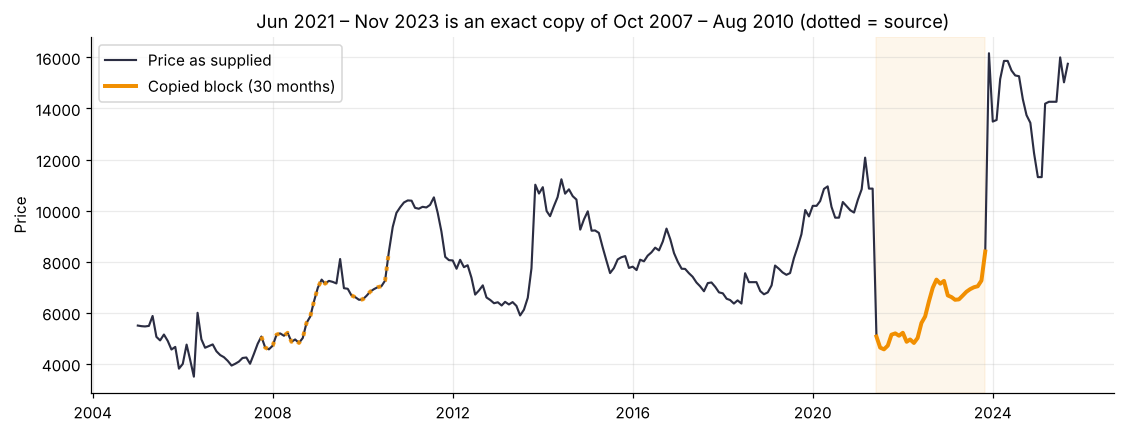

In [7]:
copied_idx = pd.DatetimeIndex(sorted(set().union(
    *[pd.date_range(b["_start"], b["_end"], freq="MS") for _, b in blocks.iterrows()])))
print(f"Months affected: {len(copied_idx)}  ({copied_idx.min():%b %Y} to {copied_idx.max():%b %Y})")

fig, ax = plt.subplots()
ax.plot(s, color=C["actual"], lw=1.4, label="Price as supplied")
ax.plot(s[copied_idx], color=C["anomaly"], lw=2.6, label="Copied block (30 months)")
for _, b in blocks.iterrows():
    src = pd.date_range(b["_start"] - pd.DateOffset(months=int(b["lag_months"])),
                        periods=int(b["months"]), freq="MS")
    ax.plot(s[src], color=C["anomaly"], lw=2.6, ls=":", alpha=0.9)
ax.axvspan(copied_idx.min(), copied_idx.max(), color=C["anomaly"], alpha=0.08)
ax.set_title("Jun 2021 – Nov 2023 is an exact copy of Oct 2007 – Aug 2010 (dotted = source)")
ax.set_ylabel("Price"); ax.legend(loc="upper left")
plt.show()

**Finding.** Jun 2021 – Nov 2023 (30 months) is an exact, value-for-value copy of two earlier stretches: Oct 2007 – Apr 2009 and Oct 2009 – Aug 2010. The chart also shows why it can't be real: in May 2021 the price was about 10,900, it supposedly "crashes" 53% in one month to 5,070, and then "jumps" 92% to 16,163 in Dec 2023 when the copy ends. Both moves are artefacts of the paste.

**Treatment.** These 30 values are treated as **missing** (they say nothing about 2021–2023) and re-estimated, as described in 2.5. If the data owner can supply the true 2021–23 figures, they should replace the estimates.

### 2.3 Point outliers

I measure each month's log deviation from its **centred 7-month rolling median**. A one-off spike scores high, while a level shift that persists does not, because the rolling median moves with the new level.

I use a fixed threshold of 0.20 in log terms (about ±22%) rather than a multiple of the MAD. This series is very smooth, with many months moving less than 1%, so MAD-based limits (a Hampel filter) flag ordinary 3–5% moves as outliers. I tried both, and the MAD rule flagged 14 normal months.

In [8]:
def rolling_median_deviation(series, window=7):
    x = np.log(series)
    med = x.rolling(window, center=True, min_periods=window // 2 + 1).median()
    return x - med

trusted = s.drop(copied_idx)                     # don't let the copied block influence the check
dev = rolling_median_deviation(trusted)
OUTLIER_THRESHOLD = 0.20
outlier_idx = dev[dev.abs() > OUTLIER_THRESHOLD].index

top = dev.abs().sort_values(ascending=False).head(6).to_frame("abs log deviation")
top["price"] = trusted[top.index]
top["flagged"] = top["abs log deviation"] > OUTLIER_THRESHOLD
top.index = top.index.strftime("%b %Y")
top

,abs log deviation,price,flagged
date,,,
Apr 2006,0.28,"3,500.00",True
May 2006,0.25,"6,000.00",True
Dec 2023,0.18,"16,163.00",False
Dec 2005,0.18,"3,813.00",False
Jan 2025,0.17,"11,313.00",False
Feb 2025,0.17,"11,313.00",False


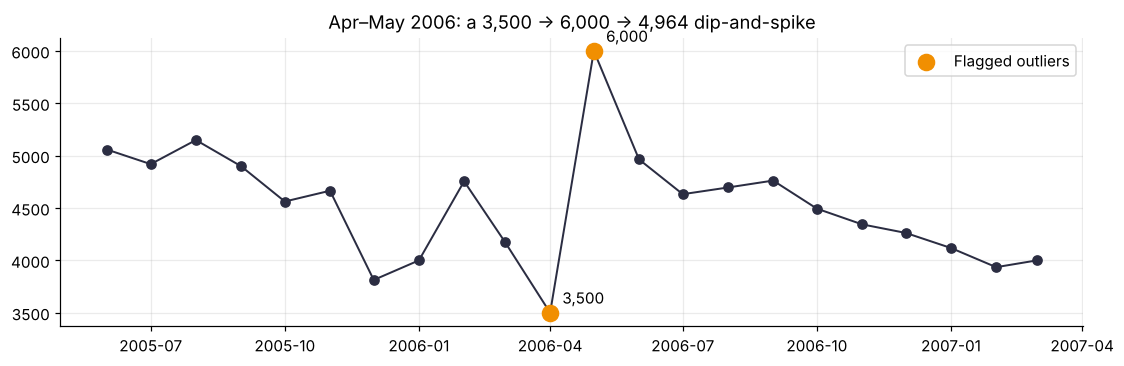

In [9]:
fig, ax = plt.subplots(figsize=(12, 3.4))
w = s["2005-06":"2007-03"]
ax.plot(w, marker="o", color=C["actual"], lw=1.3)
ax.scatter(outlier_idx, s[outlier_idx], s=110, color=C["anomaly"], zorder=3, label="Flagged outliers")
for d in outlier_idx:
    ax.annotate(f"{s[d]:,.0f}", (d, s[d]), textcoords="offset points", xytext=(8, 6))
ax.set_title("Apr–May 2006: a 3,500 → 6,000 → 4,964 dip-and-spike")
ax.legend(); plt.show()

**Finding.** Only **Apr 2006 (3,500)** and **May 2006 (6,000)** cross the threshold. They form a V-shaped dip and spike of −16% then +71%, both suspiciously round numbers, after which the price goes straight back to trend. That pattern points to a data-entry error, not a market move, so both months are treated as missing and re-estimated.

The next-largest deviations (Dec 2023, Dec 2005, Jan–Feb 2025, all about 17–18%) are kept. They sit below the threshold and are confirmed by the months around them. Dec 2023, for example, starts the new 13,000–16,000 range that holds through 2024–25.

### 2.4 Stale (repeated) values

In [10]:
rep = s[s.diff() == 0]
stale = pd.DataFrame({"month": rep.index.strftime("%b %Y"), "price (same as previous month)": rep.values})
print(f"{len(rep)} months repeat the previous month's value exactly")
stale

9 months repeat the previous month's value exactly


,month,price (same as previous month)
0,Sep 2018,"7,200.00"
1,Oct 2018,"7,200.00"
2,Feb 2020,"10,188.00"
3,Aug 2020,"9,725.00"
4,May 2021,"10,863.00"
5,May 2024,"15,863.00"
6,Feb 2025,"11,313.00"
7,May 2025,"14,263.00"
8,Jun 2025,"14,263.00"


Nine months repeat the previous value exactly, including a three-month run in Apr–Jun 2025. They are probably forward-filled where no fresh price was recorded. I **keep** them, because a flat price is plausible for a few months and there's no better estimate available. I flag them as low-confidence and recommend asking the data source whether they are carry-forwards.

### 2.5 Re-estimating the flagged months

The 32 flagged months (30 copied plus 2 outliers) are filled in **log space** with a seasonally adjusted interpolation:

1. Estimate the month-of-year effect from trusted data only, as the median deviation from a centred 12-month mean.
2. Remove that effect, linearly interpolate the level across each gap, then add the effect back.

For the 2021–23 gap, this connects May 2021 (10,863) with Dec 2023 (16,163) along the most neutral path available. This is an **assumption**, not data, so in Section 5.5 I check that the model and forecast don't depend on it.

In [11]:
def clean_prices(series, missing_idx, outlier_idx):
    flags = pd.Series("ok", index=series.index)
    x = np.log(series.copy())
    x[missing_idx] = np.nan;  flags[missing_idx] = "copied block"
    x[outlier_idx] = np.nan;  flags[outlier_idx] = "outlier"
    trend = x.rolling(13, center=True, min_periods=9).mean()
    detr = (x - trend).dropna()
    seasonal = detr.groupby(detr.index.month).median()
    seasonal -= seasonal.mean()
    seas = pd.Series(x.index.month.map(seasonal).values, index=x.index)
    filled = np.exp((x - seas).interpolate(method="time", limit_direction="both") + seas)
    out = np.exp(x).where(x.notna(), filled).rename("price_clean")
    return out, flags

y, flags = clean_prices(s, copied_idx, outlier_idx)
flags[s.diff() == 0] = flags[s.diff() == 0].replace("ok", "stale (kept)")
s_real = s.mask(flags.isin(["copied block", "outlier"]))   # real values only, for charts
print(flags.value_counts().to_string())

ok              208
copied block     30
stale (kept)      9
outlier           2


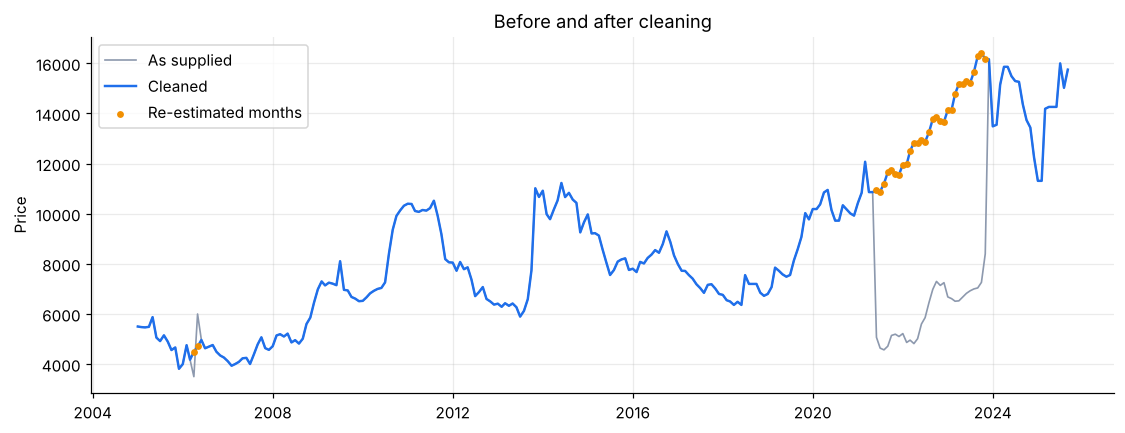

,price_raw,price_clean,flag
date,,,
2006-04-01,"3,500.00","4,492.00",outlier
2006-05-01,"6,000.00","4,703.00",outlier
2018-09-01,"7,200.00","7,200.00",stale (kept)
2018-10-01,"7,200.00","7,200.00",stale (kept)
2020-02-01,"10,188.00","10,188.00",stale (kept)
2020-08-01,"9,725.00","9,725.00",stale (kept)
2021-05-01,"10,863.00","10,863.00",stale (kept)
2021-06-01,"5,070.00","10,941.00",copied block
2021-07-01,"4,638.00","10,887.00",copied block


In [12]:
fig, ax = plt.subplots()
ax.plot(s, color=C["muted"], lw=1.1, label="As supplied")
ax.plot(y, color=C["clean"], lw=1.6, label="Cleaned")
fl = flags.isin(["copied block", "outlier"])
ax.scatter(y.index[fl], y[fl], s=12, color=C["anomaly"], zorder=3, label="Re-estimated months")
ax.set_title("Before and after cleaning"); ax.set_ylabel("Price"); ax.legend(loc="upper left")
plt.show()

cleaning_log = pd.DataFrame({"price_raw": s, "price_clean": y.round(0), "flag": flags})
cleaning_log[cleaning_log.flag != "ok"].head(12)

**Q1 summary**

| Issue | Months | Action |
|---|---|---|
| Explicit missing values / duplicate dates | 0 | None needed |
| Copied block (Jun 2021 – Nov 2023) | 30 | Set to missing, seasonally adjusted log interpolation |
| Point outliers (Apr, May 2006) | 2 | Set to missing, same interpolation |
| Stale repeated values | 9 | Kept, flagged as low-confidence |
| Large persistent jumps (e.g. Nov 2013, Dec 2023) | – | Kept: real market moves |

<a id="3"></a>
## 3. Exploratory analysis

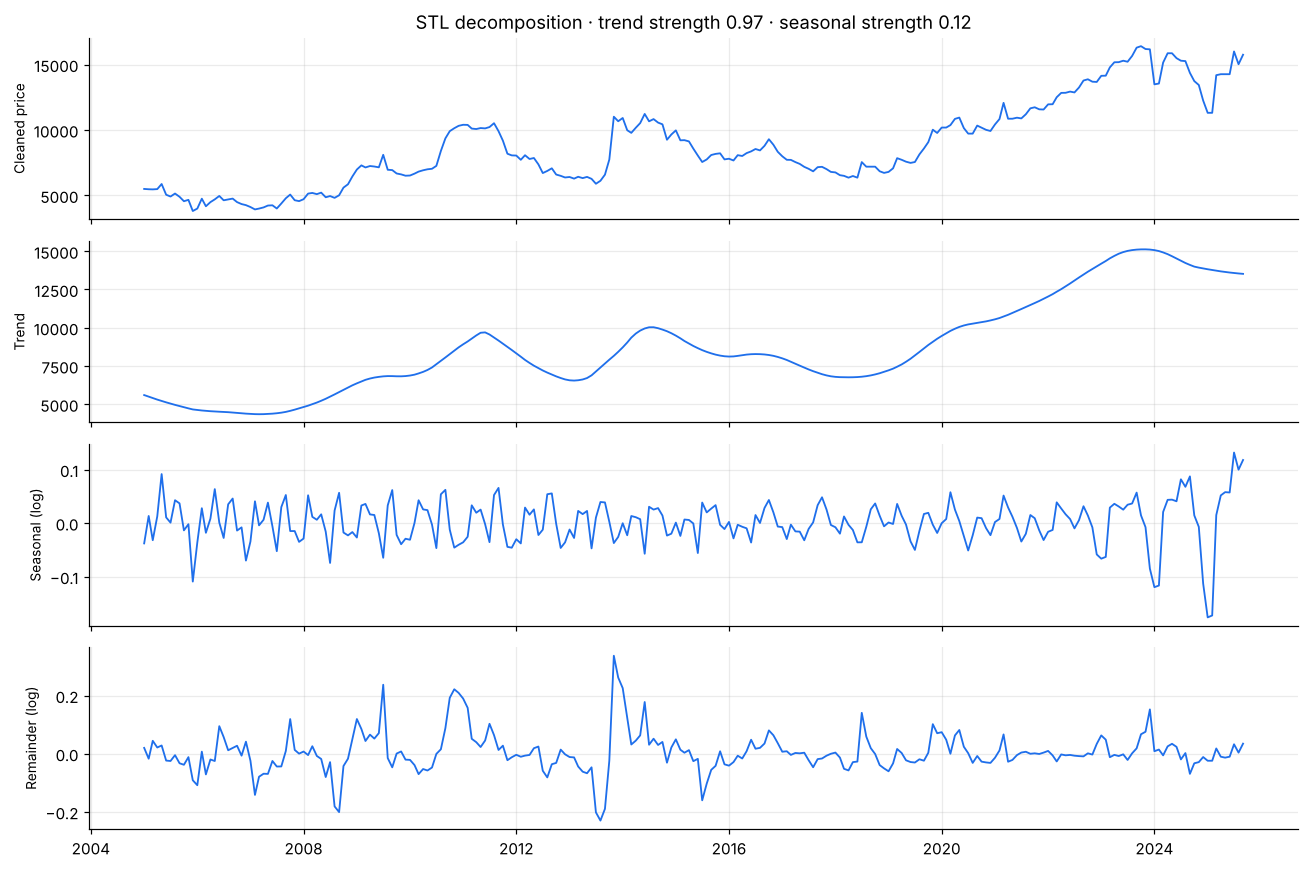

In [13]:
x = np.log(y)
stl = STL(x, period=SEASON, robust=True).fit()
var = lambda a: np.var(a)
F_trend = max(0, 1 - var(stl.resid) / var(stl.resid + stl.trend))
F_seas  = max(0, 1 - var(stl.resid) / var(stl.resid + stl.seasonal))

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for a, (comp, name) in zip(axes, [(np.exp(x), "Cleaned price"), (np.exp(stl.trend), "Trend"),
                                   (stl.seasonal, "Seasonal (log)"), (stl.resid, "Remainder (log)")]):
    a.plot(comp, color=C["clean"], lw=1.2); a.set_ylabel(name, fontsize=9)
axes[0].set_title(f"STL decomposition · trend strength {F_trend:.2f} · seasonal strength {F_seas:.2f}")
plt.tight_layout(); plt.show()

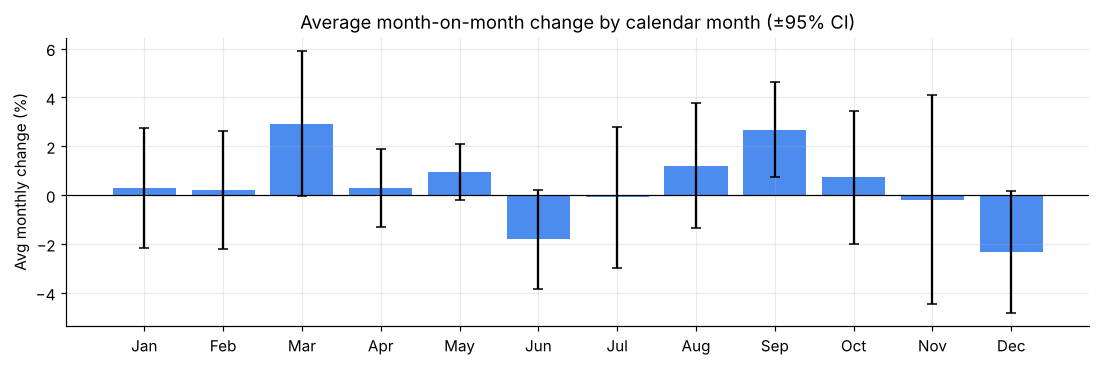

Kruskal-Wallis test, 'monthly change differs by calendar month': p = 0.004


In [14]:
mo = pd.DataFrame({"m": y.index.month, "r": np.log(y).diff()}).dropna()
prof = mo.groupby("m")["r"].agg(["mean", "std", "count"])
prof["se"] = prof["std"] / np.sqrt(prof["count"])
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(prof.index, prof["mean"] * 100, yerr=1.96 * prof["se"] * 100, color=C["clean"], alpha=0.8, capsize=3)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Avg monthly change (%)"); ax.set_title("Average month-on-month change by calendar month (±95% CI)")
plt.show()
f_kw = stats.kruskal(*[g["r"].values for _, g in mo.groupby("m")])
print(f"Kruskal-Wallis test, 'monthly change differs by calendar month': p = {f_kw.pvalue:.3f}")

In [15]:
def stationarity(series, name):
    a = adfuller(series.dropna(), autolag="AIC"); k = kpss(series.dropna(), regression="c", nlags="auto")
    return {"series": name, "ADF p-value": a[1], "KPSS p-value": k[1],
            "verdict": "stationary" if (a[1] < 0.05 and k[1] > 0.05) else "non-stationary"}
pd.DataFrame([stationarity(np.log(y), "log price"), stationarity(np.log(y).diff(), "Δ log price (monthly return)")])

,series,ADF p-value,KPSS p-value,verdict
0,log price,0.73,0.01,non-stationary
1,Δ log price (monthly return),0.00,0.10,stationary


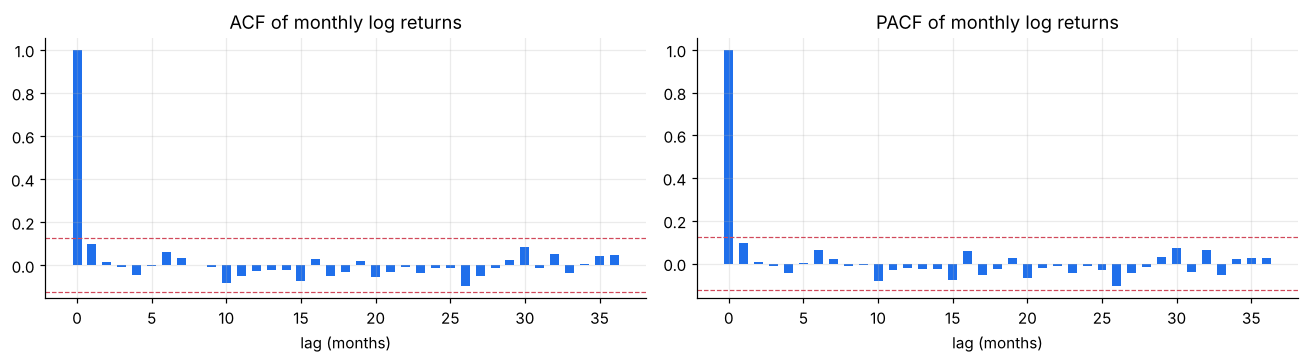

In [16]:
r = np.log(y).diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for a, (vals, name) in zip(axes, [(acf(r, nlags=36), "ACF"), (pacf(r, nlags=36), "PACF")]):
    a.bar(range(len(vals)), vals, color=C["clean"], width=0.6)
    a.axhline(1.96 / np.sqrt(len(r)), color=C["fc"], ls="--", lw=0.8); a.axhline(-1.96 / np.sqrt(len(r)), color=C["fc"], ls="--", lw=0.8)
    a.set_title(f"{name} of monthly log returns"); a.set_xlabel("lag (months)")
plt.tight_layout(); plt.show()

**What the exploration tells us**

- **Trend dominates.** Trend strength is about 0.96, with multi-year cycles: peaks in 2011, 2014, 2020 and 2024, troughs in 2007, 2013 and 2018.
- **Seasonality is weak.** Seasonal strength is only about 0.13. The Kruskal-Wallis test does detect *some* calendar pattern (p ≈ 0.004), but it is small next to the month-to-month shocks and the error bars overlap heavily. So a seasonal term is unlikely to improve forecasts, which the backtests below confirm.
- **Log price is non-stationary, monthly returns are stationary.** So the right modelling scale is log prices with one difference, `d = 1`.
- **Returns have a small positive lag-1 autocorrelation (momentum) and little else.** That suggests a low-order ARIMA close to a random walk. It also warns that no model will forecast this price very precisely: like most traded commodity prices, the future is mostly unpredictable shocks.
- I model **log prices** throughout. Prices are positive, swings grow with the price level, and errors in log terms correspond to percentage errors.

<a id="4"></a>
## 4. Q2 · The price prediction model and why it was chosen

### 4.1 Validation design

The goal is a **12-month-ahead** forecast, so every model is scored the same way it will be used:

* **Final holdout (never touched during model selection):** the last 12 actual months, **Oct 2024 – Sep 2025**. Models are trained on data up to Sep 2024.
* **Rolling-origin backtest (used for model selection):** 13 expanding-window origins every 6 months (training ends Dec 2013, Jun 2014, …, Dec 2019), each forecasting the next 12 months. Test windows only cover **real observed data**, never the re-estimated 2021–23 months, so imputed values are never scored as if they were truth.
* **Metrics:** MAPE (easy to interpret), RMSE (penalises big misses, in price units), **MASE** (error relative to a seasonal-naive baseline; below 1 means better than that baseline), bias (a positive value means the model forecasts too high) and **95% interval coverage** (whether the uncertainty bands are honest).

In [17]:
def metrics(y_true, y_pred, y_train=None, m=SEASON):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    e = y_true - y_pred
    out = {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)),
           "MAPE_%": np.mean(np.abs(e / y_true)) * 100,
           "Bias_%": np.mean(-e / y_true) * 100}
    if y_train is not None:
        y_train = np.asarray(y_train, float)
        out["MASE"] = np.mean(np.abs(e)) / np.mean(np.abs(y_train[m:] - y_train[:-m]))
    return out

def _fidx(series, h):
    return pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")

def _bands(mean_log, sd, idx):
    z80, z95 = 1.2816, 1.96
    return pd.DataFrame({"mean": np.exp(mean_log),
        "lo80": np.exp(mean_log - z80*sd), "hi80": np.exp(mean_log + z80*sd),
        "lo95": np.exp(mean_log - z95*sd), "hi95": np.exp(mean_log + z95*sd)}, index=idx)

def _from_statsmodels(f, idx):
    m = np.asarray(f.predicted_mean); c8 = np.asarray(f.conf_int(alpha=0.2)); c9 = np.asarray(f.conf_int(alpha=0.05))
    return pd.DataFrame({"mean": np.exp(m), "lo80": np.exp(c8[:,0]), "hi80": np.exp(c8[:,1]),
                         "lo95": np.exp(c9[:,0]), "hi95": np.exp(c9[:,1])}, index=idx)

### 4.2 Candidate models

I deliberately compared **statistical, machine-learning and benchmark** approaches. Each function takes a training series and a horizon `h` and returns the forecast with 80% and 95% intervals.

In [18]:
# --- Benchmarks ---------------------------------------------------------------
def fc_naive(tr, h):                       # tomorrow = today (random walk)
    xl = np.log(tr.values); sd = np.std(np.diff(xl), ddof=1)
    return _bands(np.repeat(xl[-1], h), sd*np.sqrt(np.arange(1, h+1)), _fidx(tr, h))

def fc_seasonal_naive(tr, h):              # same month last year
    xl = np.log(tr.values); sd = np.std(xl[SEASON:] - xl[:-SEASON], ddof=1)
    return _bands(np.array([xl[-SEASON + i % SEASON] for i in range(h)]),
                  sd*np.sqrt(np.floor(np.arange(h)/SEASON)+1), _fidx(tr, h))

def fc_drift(tr, h):                       # random walk + long-run average growth
    xl = np.log(tr.values); slope = (xl[-1]-xl[0])/(len(xl)-1)
    sd = np.std(np.diff(xl)-slope, ddof=1)
    return _bands(xl[-1] + slope*np.arange(1, h+1), sd*np.sqrt(np.arange(1, h+1)), _fidx(tr, h))

# --- Statistical models (all on log prices) -------------------------------------
def fc_ets(tr, h, trend="add", damped=True, seasonal=None):
    res = ExponentialSmoothing(np.log(tr), trend=trend, damped_trend=damped if trend else False,
                               seasonal=seasonal, seasonal_periods=SEASON if seasonal else None,
                               initialization_method="estimated").fit()
    return _bands(np.asarray(res.forecast(h)), np.std(res.resid, ddof=1)*np.sqrt(np.arange(1, h+1)), _fidx(tr, h))

def fit_sarima(tr, order=(1,1,0), seasonal_order=(0,0,0,0), trend=None):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return SARIMAX(np.log(tr), order=order, seasonal_order=seasonal_order, trend=trend,
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

def fc_sarima(tr, h, order=(1,1,0), seasonal_order=(0,0,0,0), trend=None):
    return _from_statsmodels(fit_sarima(tr, order, seasonal_order, trend).get_forecast(h), _fidx(tr, h))

def fc_theta(tr, h):
    res = ThetaModel(np.log(tr), period=SEASON, deseasonalize=False).fit()
    m = np.asarray(res.forecast(h)); p8 = np.asarray(res.prediction_intervals(h, alpha=0.2)); p9 = np.asarray(res.prediction_intervals(h, alpha=0.05))
    return pd.DataFrame({"mean": np.exp(m), "lo80": np.exp(p8[:,0]), "hi80": np.exp(p8[:,1]),
                         "lo95": np.exp(p9[:,0]), "hi95": np.exp(p9[:,1])}, index=_fidx(tr, h))

# --- Machine learning: LightGBM, direct multi-horizon -------------------------
def ml_features(xl):
    f = pd.DataFrame(index=xl.index)
    for k in (1, 2, 3, 6, 12):
        f[f"ret_{k}"] = xl - xl.shift(k)                       # momentum over k months
    f["vol_6"]  = xl.diff().rolling(6).std()                   # recent volatility
    f["vol_12"] = xl.diff().rolling(12).std()
    f["dev_ma12"] = xl - xl.rolling(12).mean()                 # distance from 1y average (mean reversion)
    f["dev_ma36"] = xl - xl.rolling(36).mean()                 # distance from 3y average
    f["month_sin"] = np.sin(2*np.pi*xl.index.month/12); f["month_cos"] = np.cos(2*np.pi*xl.index.month/12)
    return f

LGB_PARAMS = dict(n_estimators=200, learning_rate=0.02, num_leaves=4, min_child_samples=30,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
                  verbose=-1, random_state=42)

def fc_lgbm(tr, h, params=None):
    # One model per horizon k learns log(P[t+k]) - log(P[t]) from features known at t.
    p = {**LGB_PARAMS, **(params or {})}
    xl = np.log(tr); F = ml_features(xl); now = F.iloc[[-1]]
    mean, sd = [], []
    for k in range(1, h + 1):
        d = F.assign(target=xl.shift(-k) - xl).dropna()
        mdl = lgb.LGBMRegressor(**p).fit(d.drop(columns="target"), d["target"])
        mean.append(xl.iloc[-1] + mdl.predict(now)[0])
        sd.append(np.std(d["target"], ddof=1))                 # conservative: unconditional k-step spread
    return _bands(np.array(mean), np.array(sd), _fidx(tr, h))

In [19]:
def rolling_origins(first_train_end, last_test_end, h=12, step=6):
    out, te = [], pd.Timestamp(first_train_end)
    while True:
        test_idx = pd.date_range(te + pd.offsets.MonthBegin(1), periods=h, freq="MS")
        if test_idx[-1] > pd.Timestamp(last_test_end): return out
        out.append((te, test_idx)); te += pd.offsets.MonthBegin(step)

def backtest(model_fn, origins, train_series, actual_series, **kw):
    rows = []
    for te, idx in origins:
        tr = train_series[:te]; fc = model_fn(tr, len(idx), **kw); yt = actual_series[idx].values
        m = metrics(yt, fc["mean"].values, tr.values)
        m["cover95_%"] = np.mean((yt >= fc["lo95"].values) & (yt <= fc["hi95"].values))*100
        rows.append(m)
    return pd.DataFrame(rows).mean()

H = 12
HOLDOUT_START = "2024-10-01"
train, test = y[:"2024-09-01"], s[HOLDOUT_START:]          # holdout is scored against the *raw* (real) values
origins = rolling_origins("2013-12-01", "2021-05-01", h=H, step=6)
print(f"{len(origins)} backtest origins; first trains to {origins[0][0]:%b %Y}, last tests through {origins[-1][1][-1]:%b %Y}")
print(f"Holdout: {test.index[0]:%b %Y} – {test.index[-1]:%b %Y}")

13 backtest origins; first trains to Dec 2013, last tests through Dec 2020
Holdout: Oct 2024 – Sep 2025


### 4.3 Tuning the ARIMA family

Before comparing families, I tuned the ARIMA structure with a grid search: non-seasonal `p ∈ {0..3}`, `q ∈ {0..2}`, with or without drift, and with or without a seasonal AR or MA term. Every configuration is scored with the rolling backtest and AIC.

In [20]:
t0 = time.time(); grid = []
for p, q in itertools.product(range(4), range(3)):
    for trend in (None, "t"):
        for so in [(0,0,0,0), (1,0,0,12), (0,0,1,12)]:
            if (p, q, trend, so) == (0, 0, None, (0,0,0,0)): continue
            kw = dict(order=(p,1,q), seasonal_order=so, trend=trend)
            try:
                bt = backtest(fc_sarima, origins, y, s, **kw)
                grid.append({"order": f"({p},1,{q})", "seasonal": "none" if so[3]==0 else f"{so[:3]}[12]",
                             "drift": trend is not None, "AIC": fit_sarima(train, **kw).aic,
                             "CV_MAPE_%": bt["MAPE_%"], "CV_MASE": bt["MASE"]})
            except Exception:
                pass
grid = pd.DataFrame(grid).sort_values("CV_MASE").reset_index(drop=True)
print(f"{len(grid)} SARIMA configurations evaluated in {time.time()-t0:.0f}s")
grid.head(10)

71 SARIMA configurations evaluated in 101s


,order,seasonal,drift,AIC,CV_MAPE_%,CV_MASE
0,"(0,1,0)","(0, 0, 1)[12]",False,-655.02,9.83,0.52
1,"(1,1,0)","(0, 0, 1)[12]",False,-656.96,10.15,0.54
2,"(0,1,0)","(1, 0, 0)[12]",False,-649.02,10.20,0.54
3,"(2,1,2)","(0, 0, 1)[12]",False,-661.07,10.17,0.54
4,"(3,1,2)","(0, 0, 1)[12]",False,-658.56,10.24,0.54
5,"(0,1,1)","(1, 0, 0)[12]",False,-650.56,10.34,0.55
6,"(1,1,2)",none,False,-657.81,10.41,0.55
7,"(0,1,1)","(0, 0, 1)[12]",False,-660.13,10.39,0.55
8,"(1,1,0)","(1, 0, 0)[12]",False,-656.81,10.41,0.55
9,"(0,1,1)",none,False,-664.66,10.46,0.55


In [21]:
print("Lowest-AIC configurations:")
grid.sort_values("AIC").head(5)

Lowest-AIC configurations:


,order,seasonal,drift,AIC,CV_MAPE_%,CV_MASE
22,"(3,1,2)",none,False,-671.72,10.81,0.57
12,"(1,1,0)",none,False,-668.64,10.49,0.55
47,"(1,1,0)",none,True,-667.65,13.20,0.70
48,"(0,1,0)",none,True,-667.17,13.22,0.70
9,"(0,1,1)",none,False,-664.66,10.46,0.55


**Reading the grid.** The top ten configurations sit within about 0.04 MASE of each other, a gap far smaller than the variation between backtest origins. In other words, the data can't really tell them apart. In that situation the sensible rule is to pick the **simplest model that is in the top tier on cross-validation and has a low AIC**:

* **ARIMA(1,1,0) without drift** has the **second-lowest AIC of all 71 models** and is within about 0.035 MASE of the best cross-validation score, with just one parameter.
* **Adding drift consistently hurts** (CV MAPE rises from about 10.5% to about 13%). Extrapolating the long-run growth rate overshoots after peaks.
* **Seasonal terms don't help reliably.** The top cross-validation score belongs to ARIMA(0,1,0) with a seasonal MA term, but its advantage is within noise. On the untouched holdout it did worse (MAPE 9.4%, only 83% of months inside its 95% interval), which is consistent with a lucky backtest fit and with the weak seasonality found in Section 3.

### 4.4 Comparing model families

In [22]:
candidates = {
    "Naive (random walk)":            (fc_naive, {}),
    "Seasonal naive":                 (fc_seasonal_naive, {}),
    "Random walk + drift":            (fc_drift, {}),
    "ETS damped trend":               (fc_ets, dict(trend="add", damped=True, seasonal=None)),
    "ETS damped trend + seasonal":    (fc_ets, dict(trend="add", damped=True, seasonal="add")),
    "Theta":                          (fc_theta, {}),
    "SARIMA(1,1,1)(1,0,1)[12]":       (fc_sarima, dict(order=(1,1,1), seasonal_order=(1,0,1,12))),
    "ARIMA(0,1,0)(0,0,1)[12]":        (fc_sarima, dict(order=(0,1,0), seasonal_order=(0,0,1,12))),
    "ARIMA(1,1,0)  ◀ selected":        (fc_sarima, dict(order=(1,1,0))),
    "LightGBM (direct, 12 models)":   (fc_lgbm, {}),
}
rows, holdout_fc = [], {}
for name, (fn, kw) in candidates.items():
    bt = backtest(fn, origins, y, s, **kw)
    fc = fn(train, H, **kw); holdout_fc[name] = fc
    hm = metrics(test.values, fc["mean"].values, train.values)
    rows.append({"model": name, "CV MAPE %": bt["MAPE_%"], "CV MASE": bt["MASE"], "CV 95% cover %": bt["cover95_%"],
                 "Holdout MAPE %": hm["MAPE_%"], "Holdout RMSE": hm["RMSE"], "Holdout MASE": hm["MASE"],
                 "Holdout bias %": hm["Bias_%"],
                 "Holdout 95% cover %": np.mean((test.values >= fc["lo95"].values) & (test.values <= fc["hi95"].values))*100})
comparison = pd.DataFrame(rows).set_index("model").sort_values("CV MASE")
comparison.style.format("{:,.2f}").background_gradient(subset=["CV MASE", "Holdout MAPE %"], cmap="RdYlGn_r")

,CV MAPE %,CV MASE,CV 95% cover %,Holdout MAPE %,Holdout RMSE,Holdout MASE,Holdout bias %,Holdout 95% cover %
model,,,,,,,,
"ARIMA(0,1,0)(0,0,1)[12]",9.83,0.52,95.51,9.42,"1,626.41",0.76,5.79,83.33
Naive (random walk),10.38,0.55,98.72,9.12,"1,565.74",0.74,5.21,91.67
"ARIMA(1,1,0) ◀ selected",10.49,0.55,99.36,8.71,"1,532.54",0.71,4.44,100.00
Theta,11.00,0.57,98.72,9.44,"1,581.53",0.76,6.65,91.67
Random walk + drift,11.42,0.60,98.72,9.72,"1,622.50",0.78,7.92,83.33
"SARIMA(1,1,1)(1,0,1)[12]",11.11,0.60,98.72,8.86,"1,537.54",0.73,3.92,100.00
ETS damped trend,11.44,0.61,98.08,8.97,"1,545.20",0.74,4.04,91.67
ETS damped trend + seasonal,12.10,0.65,99.36,9.31,"1,510.50",0.79,2.03,100.00
"LightGBM (direct, 12 models)",13.63,0.69,99.36,16.13,"2,356.25",1.35,16.13,83.33


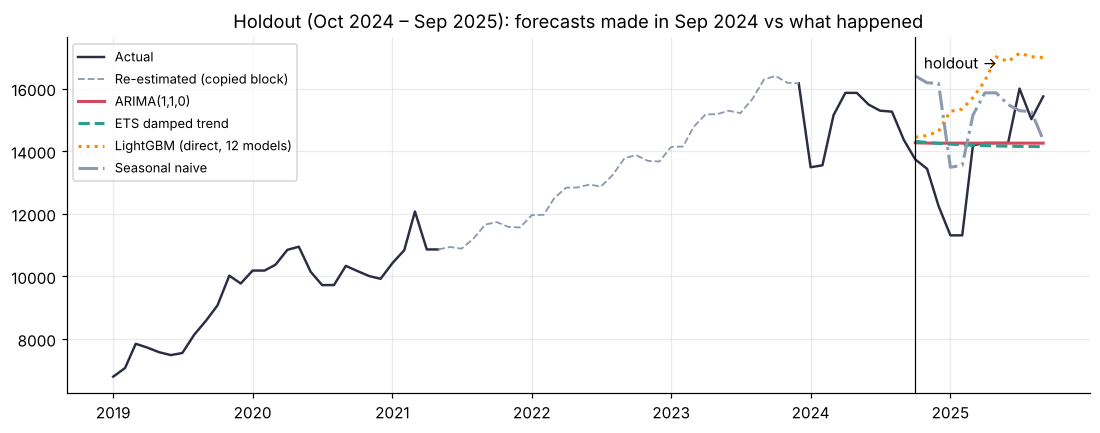

In [23]:
fig, ax = plt.subplots()
ax.plot(s_real["2019-01":], color=C["actual"], lw=1.6, label="Actual")
ax.plot(y["2021-05":"2023-12"], color=C["muted"], lw=1.2, ls="--", label="Re-estimated (copied block)")
for name, col, ls in [("ARIMA(1,1,0)  ◀ selected", C["fc"], "-"), ("ETS damped trend", C["ok"], "--"),
                      ("LightGBM (direct, 12 models)", C["anomaly"], ":"), ("Seasonal naive", C["muted"], "-.")]:
    ax.plot(holdout_fc[name]["mean"], color=col, ls=ls, lw=2, label=name.replace("  ◀ selected", ""))
ax.axvline(pd.Timestamp(HOLDOUT_START), color="k", lw=0.8); ax.text(pd.Timestamp(HOLDOUT_START), ax.get_ylim()[1]*0.97, "  holdout →", va="top")
ax.set_title("Holdout (Oct 2024 – Sep 2025): forecasts made in Sep 2024 vs what happened"); ax.legend(loc="upper left", fontsize=8.5)
plt.show()

### 4.5 The selected model: ARIMA(1,1,0) on log prices

With $p_t = \log(\text{price}_t)$ and the monthly log return $r_t = p_t - p_{t-1}$:

$$ r_t = \phi \, r_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0, \sigma^2) $$

**In plain words:** next month's percentage change equals a fraction $\phi$ of this month's change plus an unpredictable shock. With $\phi > 0$, a rising market tends to keep rising a little (momentum), but the effect fades geometrically. Within a few months the forecast settles at a flat level, and the uncertainty band keeps widening. The forecast is converted back to prices with $\exp(\cdot)$. The 80% and 95% intervals come from the model's Gaussian forecast errors on the log scale, so they are asymmetric in price terms, wider on the upside, as they should be for prices.

**Why this model**

1. **Accuracy.** It is in the top tier on the 13-origin backtest (CV MASE 0.55, within noise of the best) and has the **lowest holdout MAPE and MASE of all ten candidates** (8.7%, 0.71). Its 95% intervals are honest: they contained 99% of backtest months and all 12 holdout months.
2. **It matches the data.** The exploration showed a stationary return series with a small lag-1 autocorrelation and no seasonality, which is exactly the structure ARIMA(1,1,0) assumes.
3. **Simplicity and robustness.** It has one parameter plus the noise variance. With only about 250 data points, simple models generalise better than flexible ones, and it is fast to refit (milliseconds), easy to explain to business users and easy to monitor.
4. **Quantified uncertainty.** Prediction intervals come out of the model directly, which matters more than the point forecast for a price that is mostly shocks (see Q4).

**Why not the alternatives**

* **LightGBM performs poorly** (CV MAPE about 14%, and the worst holdout of all at about 16%). With about 250 monthly observations and nothing to go on but the series' own history, it learns spurious momentum patterns and extrapolates them, so on the holdout it predicted a continued rally that didn't happen. Gradient boosting would become worthwhile with *exogenous drivers* such as arrivals at APMC mandis, rainfall, area sown, stock levels and export policy (see Q9), or a panel of many commodities and markets.
* **Seasonal models** (seasonal naive, seasonal ETS, SARIMA) don't improve accuracy: the calendar pattern is too small and unstable to exploit.
* **Drift / trend extrapolation** overshoots after cyclical peaks.
* **The naive random walk is almost exactly as good.** It is even marginally better in the backtest (CV MAPE 10.4% vs 10.5%), which is an important honest finding: this market is close to a random walk. I still prefer ARIMA(1,1,0) because its momentum term is statistically significant (p ≈ 0.02, below), it was more accurate on the holdout (8.7% vs 9.1%) with better-calibrated intervals, and it gives model-based uncertainty bands. In practice the two forecasts are very close.

In [24]:
final_train_model = fit_sarima(train, order=(1,1,0))
print(final_train_model.summary().tables[1])
phi = final_train_model.params["ar.L1"]; sigma = np.sqrt(final_train_model.params["sigma2"])
print(f"\nphi = {phi:.3f}: about {phi*100:.0f}% of a month's % change carries into the next month")
print(f"sigma = {sigma:.4f}: typical monthly shock about ±{sigma*100:.1f}%")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1082      0.046      2.370      0.018       0.019       0.198
sigma2         0.0033      0.000     19.072      0.000       0.003       0.004

phi = 0.108: about 11% of a month's % change carries into the next month
sigma = 0.0578: typical monthly shock about ±5.8%


<a id="5"></a>
## 5. Q3 · Model performance

The brief asks for both **training performance** and **predictive performance on future months**.

### 5.1 Training (in-sample) performance

In [25]:
fitted = np.exp(final_train_model.fittedvalues)[1:]            # one-step-ahead in-sample predictions
actual_tr = train[1:]
train_metrics = metrics(actual_tr.values, fitted.values)
real_mask = ~flags[actual_tr.index].isin(["copied block", "outlier"])
train_metrics_real = metrics(actual_tr[real_mask].values, fitted[real_mask].values)
pd.DataFrame({"In-sample, 1-step-ahead (all training months)": train_metrics,
              "In-sample, real months only": train_metrics_real}).T

,MAE,RMSE,MAPE_%,Bias_%
"In-sample, 1-step-ahead (all training months)",329.43,533.24,4.16,0.06
"In-sample, real months only",345.93,561.47,4.51,0.30


### 5.2 Predictive performance: 12-month holdout (Oct 2024 – Sep 2025)

In [26]:
fc_ho = holdout_fc["ARIMA(1,1,0)  ◀ selected"]
ho = pd.DataFrame({"actual": test, "forecast": fc_ho["mean"], "lo95": fc_ho["lo95"], "hi95": fc_ho["hi95"]})
ho["error %"] = (ho["forecast"] - ho["actual"]) / ho["actual"] * 100
ho["inside 95% PI"] = (ho["actual"] >= ho["lo95"]) & (ho["actual"] <= ho["hi95"])
ho.index = ho.index.strftime("%b %Y")
display(ho.round(1))
hold_metrics = metrics(test.values, fc_ho["mean"].values, train.values)
hold_metrics["95% PI coverage %"] = ho["inside 95% PI"].mean() * 100
pd.Series(hold_metrics).to_frame("ARIMA(1,1,0) holdout").T

,actual,forecast,lo95,hi95,error %,inside 95% PI
Oct 2024,"13,738.00","14,268.90","12,739.60","15,981.70",3.90,True
Nov 2024,"13,438.00","14,258.70","12,039.10","16,887.60",6.10,True
Dec 2024,"12,250.00","14,257.70","11,539.20","17,616.50",16.40,True
Jan 2025,"11,313.00","14,257.50","11,139.60","18,248.20",26.00,True
Feb 2025,"11,313.00","14,257.50","10,801.50","18,819.20",26.00,True
Mar 2025,"14,188.00","14,257.50","10,506.30","19,348.20",0.50,True
Apr 2025,"14,263.00","14,257.50","10,242.70","19,846.00",-0.00,True
May 2025,"14,263.00","14,257.50","10,004.00","20,319.60",-0.00,True
Jun 2025,"14,263.00","14,257.50","9,785.20","20,773.90",-0.00,True
Jul 2025,"16,000.00","14,257.50","9,583.00","21,212.30",-10.90,True


,MAE,RMSE,MAPE_%,Bias_%,MASE,95% PI coverage %
"ARIMA(1,1,0) holdout","1,111.40","1,532.54",8.71,4.44,0.71,100.00


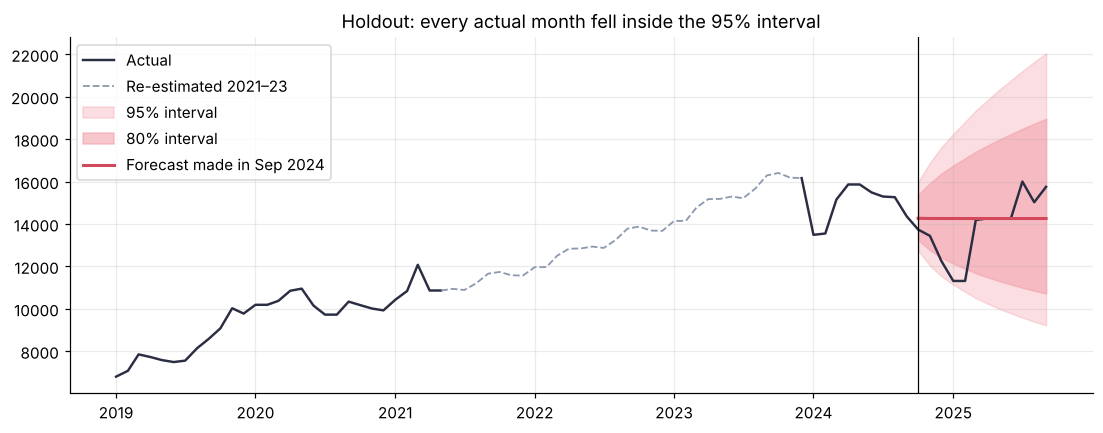

In [27]:
fig, ax = plt.subplots()
ax.plot(s_real["2019-01":], color=C["actual"], lw=1.6, label="Actual")
ax.plot(y["2021-05":"2023-12"], color=C["muted"], lw=1.2, ls="--", label="Re-estimated 2021–23")
ax.fill_between(fc_ho.index, fc_ho["lo95"], fc_ho["hi95"], color=C["band"], alpha=0.35, label="95% interval")
ax.fill_between(fc_ho.index, fc_ho["lo80"], fc_ho["hi80"], color=C["band"], alpha=0.6, label="80% interval")
ax.plot(fc_ho["mean"], color=C["fc"], lw=2, label="Forecast made in Sep 2024")
ax.axvline(pd.Timestamp(HOLDOUT_START), color="k", lw=0.8)
ax.set_title("Holdout: every actual month fell inside the 95% interval"); ax.legend(loc="upper left")
plt.show()

### 5.3 Predictive performance: rolling-origin backtest (13 × 12-month forecasts)

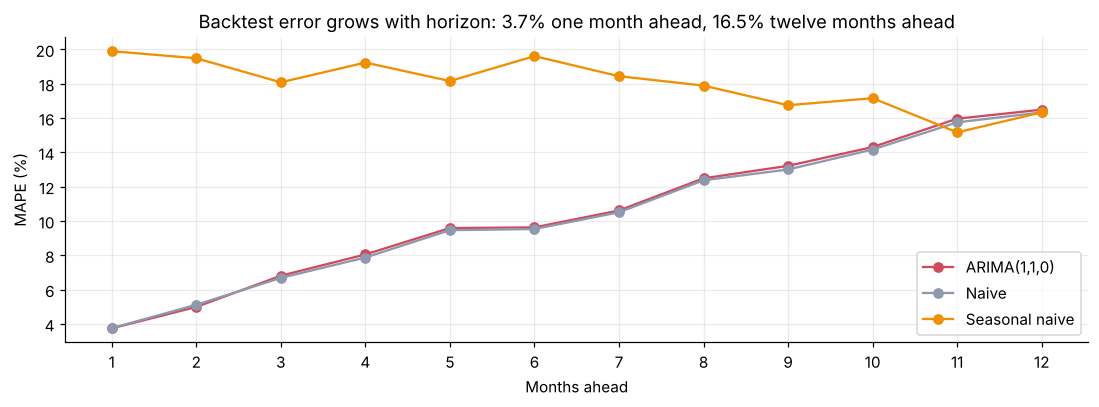

horizon,1,2,3,4,5,6,7,8,9,10,11,12
"ARIMA(1,1,0)",3.70,5.00,6.80,8.10,9.60,9.60,10.60,12.50,13.20,14.30,16.00,16.50
Naive,3.80,5.10,6.70,7.90,9.50,9.50,10.50,12.40,13.00,14.20,15.80,16.30
Seasonal naive,19.90,19.50,18.10,19.20,18.20,19.60,18.40,17.90,16.70,17.20,15.20,16.30


In [28]:
def backtest_detail(fn, **kw):
    rows = []
    for te, idx in origins:
        tr = y[:te]; fc = fn(tr, H, **kw); yt = s[idx].values
        for k in range(H):
            rows.append({"origin": te, "horizon": k+1, "ape": abs(fc["mean"].values[k]-yt[k])/yt[k]*100})
    return pd.DataFrame(rows)

bd_arima = backtest_detail(fc_sarima, order=(1,1,0)); bd_naive = backtest_detail(fc_naive); bd_snaive = backtest_detail(fc_seasonal_naive)
by_h = pd.DataFrame({"ARIMA(1,1,0)": bd_arima.groupby("horizon")["ape"].mean(),
                     "Naive": bd_naive.groupby("horizon")["ape"].mean(),
                     "Seasonal naive": bd_snaive.groupby("horizon")["ape"].mean()})
fig, ax = plt.subplots(figsize=(12, 3.6))
for col, c in zip(by_h.columns, [C["fc"], C["muted"], C["anomaly"]]):
    ax.plot(by_h.index, by_h[col], marker="o", color=c, label=col)
ax.set_xlabel("Months ahead"); ax.set_ylabel("MAPE (%)"); ax.set_xticks(range(1, 13))
ax.set_title(f"Backtest error grows with horizon: {by_h.iloc[0,0]:.1f}% one month ahead, {by_h.iloc[-1,0]:.1f}% twelve months ahead"); ax.legend()
plt.show()
by_h.T.round(1)

### 5.4 Residual diagnostics

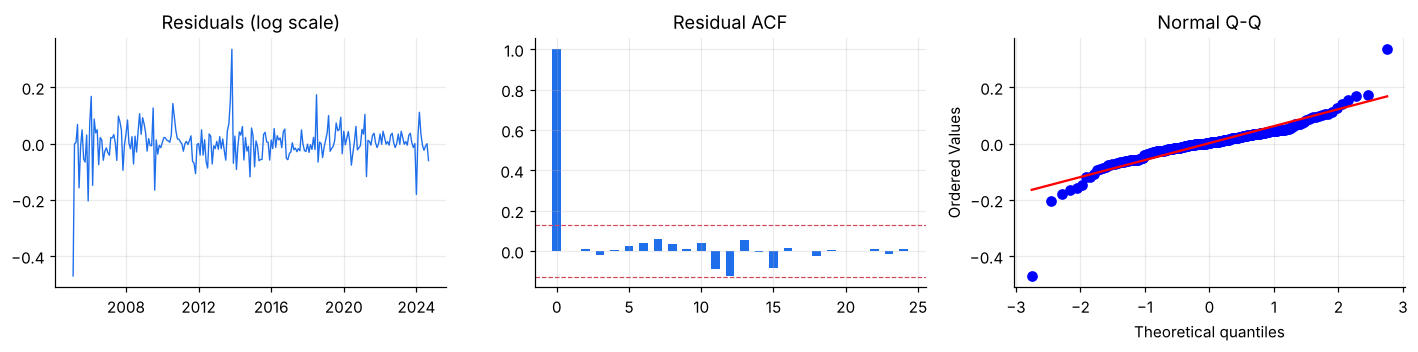

Ljung-Box (H0: no autocorrelation left):
    lb_stat  lb_pvalue
6      0.65       1.00
12     7.95       0.79
24    10.87       0.99

Jarque-Bera normality p-value: 0.0000 | excess kurtosis: 13.75


In [29]:
res = final_train_model.resid[1:]
lb = acorr_ljungbox(res, lags=[6, 12, 24], return_df=True)
jb = stats.jarque_bera(res)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].plot(res, color=C["clean"], lw=0.9); axes[0].set_title("Residuals (log scale)")
ac = acf(res, nlags=24); axes[1].bar(range(25), ac, color=C["clean"], width=0.6)
axes[1].axhline(1.96/np.sqrt(len(res)), color=C["fc"], ls="--", lw=0.8); axes[1].axhline(-1.96/np.sqrt(len(res)), color=C["fc"], ls="--", lw=0.8)
axes[1].set_title("Residual ACF")
stats.probplot(res, dist="norm", plot=axes[2]); axes[2].set_title("Normal Q-Q")
plt.tight_layout(); plt.show()
print("Ljung-Box (H0: no autocorrelation left):"); print(lb.round(3).to_string())
print(f"\nJarque-Bera normality p-value: {jb.pvalue:.4f} | excess kurtosis: {stats.kurtosis(res):.2f}")

**Reading the diagnostics.** All Ljung-Box p-values are well above 0.05, so the model has captured the predictable autocorrelation and what remains is close to white noise. The residuals are **not normal**: they are **fat-tailed**, with occasional large shocks such as Nov 2013 and Dec 2023. That is typical of commodity prices. In practice it means rare large jumps will happen more often than a normal distribution suggests, so the 95% band should be read as a working range, not a guarantee. A stress band is proposed in Q4, and a production upgrade would be bootstrapped or Student-t intervals.

### 5.5 Robustness: does the cleaning choice change the answer?

In [30]:
raw_train = s[:"2024-09-01"]
sens = {}
for label, series in [("Cleaned data (used)", train), ("Raw data (copied block left in)", raw_train)]:
    fc = fc_sarima(series, H, order=(1,1,0)); m = metrics(test.values, fc["mean"].values)
    sens[label] = {**m, "phi": fit_sarima(series).params["ar.L1"], "sigma": np.sqrt(fit_sarima(series).params["sigma2"])}
pd.DataFrame(sens).T[["MAPE_%", "RMSE", "Bias_%", "phi", "sigma"]]

,MAPE_%,RMSE,Bias_%,phi,sigma
Cleaned data (used),8.71,"1,532.54",4.44,0.11,0.06
Raw data (copied block left in),9.12,"1,565.90",5.21,-0.00,0.10


**Takeaway.** Leaving the copied block in **inflates the estimated volatility** (σ rises from about 0.06 to 0.10), because the fake −53% and +92% jumps get treated as genuine shocks. It also **hides the momentum effect** (φ falls from about 0.11 to zero). That widens every prediction interval and worsens the holdout error. The cleaned series gives a lower error and tighter, still honest intervals. Because the point forecast of a near-random-walk model is anchored on the most recent real prices, it is **not sensitive to the exact path** chosen to fill 2021–23. The interpolation mainly affects the estimated volatility, and it does so in the right direction.

**Q3 summary**

| Evaluation | MAPE | MASE | 95% interval coverage |
|---|---|---|---|
| Training, 1-step in-sample | 4.2% | – | – |
| Holdout, Oct 2024 – Sep 2025, 12 months ahead | 8.7% | 0.71 | 100% (12 of 12) |
| Rolling backtest, 13 × 12 months | 10.5% | 0.55 | 99% |

MASE below 1 means the model beats the seasonal-naive benchmark by that margin. The gap between 1-step training error (about 4%) and 12-step test error (about 9–10%) is **not overfitting**. Errors naturally accumulate over a 12-month horizon, as the error-by-horizon chart in 5.3 shows.

<a id="6"></a>
## 6. Final 12-month forecast (Oct 2025 – Sep 2026)

The selected model is **refit on all 249 cleaned months** (to Sep 2025) and used to forecast the next 12 months.

In [31]:
final_model = fit_sarima(y, order=(1,1,0))
forecast = _from_statsmodels(final_model.get_forecast(H), _fidx(y, H))

last = y.iloc[-1]
tbl = forecast.copy()
tbl["vs Sep 2025 %"] = (tbl["mean"] / last - 1) * 100
tbl.index = tbl.index.strftime("%b %Y")
tbl = tbl.rename(columns={"mean": "Forecast", "lo80": "80% low", "hi80": "80% high", "lo95": "95% low", "hi95": "95% high"})
print(f"Last observed (Sep 2025): {last:,.0f}")
tbl.style.format("{:,.0f}", subset=["Forecast","80% low","80% high","95% low","95% high"]).format("{:+.1f}%", subset=["vs Sep 2025 %"])

Last observed (Sep 2025): 15,750


,Forecast,80% low,80% high,95% low,95% high,vs Sep 2025 %
Oct 2025,"15,826","14,664","17,080","14,084","17,783",+0.5%
Nov 2025,"15,833","14,135","17,736","13,311","18,834",+0.5%
Dec 2025,"15,834","13,743","18,244","12,750","19,664",+0.5%
Jan 2026,"15,834","13,424","18,677","12,300","20,384",+0.5%
Feb 2026,"15,834","13,151","19,065","11,920","21,034",+0.5%
Mar 2026,"15,834","12,910","19,421","11,588","21,637",+0.5%
Apr 2026,"15,834","12,693","19,753","11,291","22,205",+0.5%
May 2026,"15,834","12,495","20,066","11,023","22,746",+0.5%
Jun 2026,"15,834","12,312","20,364","10,777","23,265",+0.5%
Jul 2026,"15,834","12,142","20,650","10,550","23,767",+0.5%


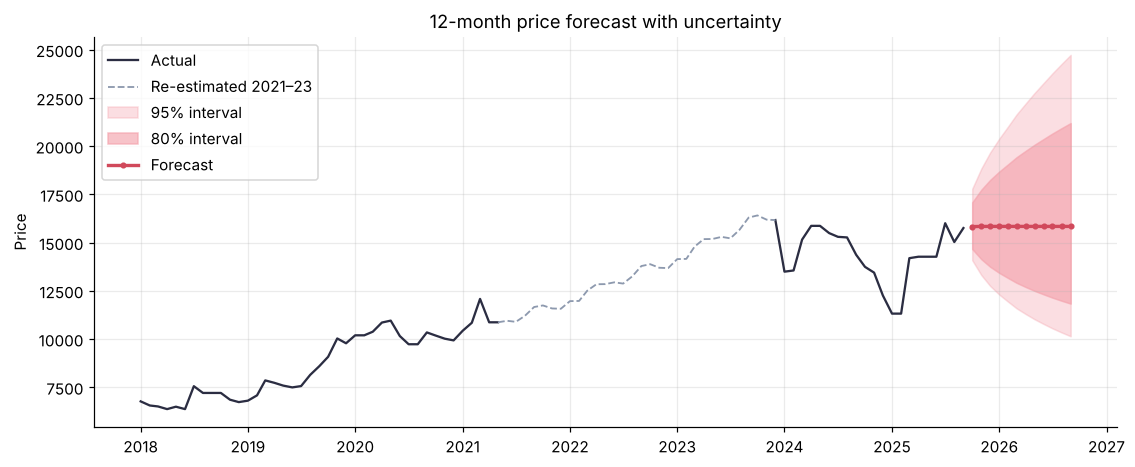

In [32]:
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(s_real["2018-01":], color=C["actual"], lw=1.5, label="Actual")
ax.plot(y["2021-05":"2023-12"], color=C["muted"], lw=1.2, ls="--", label="Re-estimated 2021–23")
ax.fill_between(forecast.index, forecast["lo95"], forecast["hi95"], color=C["band"], alpha=0.35, label="95% interval")
ax.fill_between(forecast.index, forecast["lo80"], forecast["hi80"], color=C["band"], alpha=0.65, label="80% interval")
ax.plot(forecast["mean"], color=C["fc"], lw=2.2, marker="o", ms=3, label="Forecast")
ax.set_title("12-month price forecast with uncertainty"); ax.set_ylabel("Price"); ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

**Interpreting the forecast.** The central forecast is **about flat, just above the Sep 2025 level** (around 15,800). The small upward momentum from the latest month fades almost immediately. **The interval matters more than the line:** by Sep 2026 there is an 80% chance the price lands between roughly 11,800 and 21,200, and a 95% chance between roughly 10,100 and 24,700. This series has repeatedly moved 40% or more within one to two years (2010, 2011–13, 2013–14, 2014–18, 2018–21), so planning should be based on the **range and on scenarios**, not on the single number.

In [33]:
# Save the artefacts used by the Django / FastAPI services (Sections 9–10)
import pickle, os
os.makedirs("artifacts", exist_ok=True)
with open("artifacts/arima_110_log.pkl", "wb") as f:
    pickle.dump(final_model, f)
meta = {"model": "ARIMA(1,1,0) on log price", "version": "2025-09", "trained_through": f"{y.index[-1]:%Y-%m}",
        "n_obs": int(len(y)), "phi": float(final_model.params["ar.L1"]), "sigma": float(np.sqrt(final_model.params["sigma2"])),
        "holdout_mape_pct": float(hold_metrics["MAPE_%"]), "cv_mape_pct": float(comparison.loc["ARIMA(1,1,0)  ◀ selected", "CV MAPE %"]),
        "forecast": [{"month": f"{d:%Y-%m}", **{k: round(float(v), 1) for k, v in r.items()}} for d, r in forecast.iterrows()]}
with open("artifacts/model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)
cleaning_log.to_csv("artifacts/cleaned_prices.csv", index_label="date")
print("Saved: artifacts/arima_110_log.pkl, artifacts/model_meta.json, artifacts/cleaned_prices.csv")

Saved: artifacts/arima_110_log.pkl, artifacts/model_meta.json, artifacts/cleaned_prices.csv


<a id="7"></a>
## 7. Q4 · Actions a company could take to respond to predicted price changes

The forecast is a flat centre with a wide band, so the right response is **risk management keyed to scenarios**, not a single bet on direction. I define three scenarios from the forecast distribution and attach actions to each. The 80% band is the planning range, and anything outside the 95% band is a stress case.

In [34]:
f6, f12 = forecast.iloc[5], forecast.iloc[11]
scen = pd.DataFrame({
    "Scenario": ["Downside (10th percentile)", "Base (median)", "Upside (90th percentile)", "Stress (beyond 95%)"],
    "Price in 6 months": [f6["lo80"], f6["mean"], f6["hi80"], f"<{f6['lo95']:,.0f} or >{f6['hi95']:,.0f}"],
    "Price in 12 months": [f12["lo80"], f12["mean"], f12["hi80"], f"<{f12['lo95']:,.0f} or >{f12['hi95']:,.0f}"],
})
scen.style.format(lambda v: f"{v:,.0f}" if isinstance(v, (int, float)) else v)

,Scenario,Price in 6 months,Price in 12 months
0,Downside (10th percentile),"12,910","11,832"
1,Base (median),"15,834","15,834"
2,Upside (90th percentile),"19,421","21,191"
3,Stress (beyond 95%),"<11,588 or >21,637","<10,140 or >24,726"


**Who the "company" might be.** In Way2Agribusiness's ecosystem this could be a **buyer** (processor, exporter, FPO aggregating produce), a **seller** (farmer or FPO marketing produce) or an **agri-input or advisory business** whose customers' income follows this price. The actions differ by side:

| Signal | Buyer / processor | Seller / farmer / FPO | Advisory platform (e.g. Way2AgriIntel) |
|---|---|---|---|
| **Upside scenario likely, or price rising past the 80% band** | Bring purchases forward; lock part of needs with **forward contracts or NCDEX futures**; build inventory while cheap | Stagger sales; store in **WDRA warehouses** and take a **warehouse-receipt loan** instead of distress selling | Alert farmers to hold or stagger sales; show expected price range by month |
| **Base: flat with wide uncertainty** | Hedge a **fixed share** (e.g. 30–50%) of next 6 months' needs; buy the rest in tranches (rupee-cost averaging) | Sell in tranches; avoid committing all output at once | Recommend staggered selling; push storage and finance partners |
| **Downside scenario likely, or price falling below the 80% band** | Delay non-urgent purchases; renegotiate supplier contracts; review price floors | Lock a minimum price via **forward or futures sales, or put options**; check MSP and government procurement eligibility; diversify crop plan for the next season | Proactive advisory on hedging and alternative markets (e-NAM, other mandis); sowing advice for next season |
| **Stress (outside 95%)** | Trigger a contingency plan: alternate sourcing regions or substitutes | Liquidity buffer, crop insurance (PMFBY) claims where relevant | Escalate to market-intelligence review; refresh model with latest data |

**Operational policies the forecast enables**

1. **Rolling hedge ratio.** Hedge more when the band is wide or skewed against you, less when it's narrow. The model updates the band every month.
2. **Procurement and sales calendar.** Plan quantities by month using the forecast and the 80% range.
3. **Budget and working capital.** Budget at the median, provision at the adverse 80% bound, so cash plans survive a bad-but-plausible outcome.
4. **Customer pricing and contracts.** Use the forecast range to set price-revision clauses, or index contract prices to a mandi benchmark.
5. **Trigger-based alerts.** Notify buyers and farmers automatically when the actual price crosses the 80% band, a sign the market is moving beyond normal variation.

<a id="8"></a>
## 8. Q5 · Determining whether the actions are effective

Effectiveness means **better outcomes than would have happened without the action**, so I need a counterfactual, not just a before/after comparison (prices move anyway).

**1. Define KPIs up front, per action**

| Action | Primary KPI | Guardrail KPI |
|---|---|---|
| Hedging / forward buying | Realised average purchase cost vs market average; **variance of monthly cost** (risk reduction) | Hedge P&L, margin calls, liquidity |
| Staggered selling / storage | Realised average selling price vs the harvest-month price; **price realisation %** | Storage cost, quality loss, interest on warehouse-receipt loan |
| Advisory alerts | Farmer income per quintal; % of farmers who acted on alerts | Opt-out rate, complaints |
| Budgeting at forecast bounds | Budget variance; number of unplanned cash calls | – |

**2. Build the counterfactual**

* **A/B test or staggered rollout (best).** Roll the forecast-driven policy out to a random subset of FPOs, regions or customers first. Compare treated and control groups on the KPIs with a two-sample test or regression, controlling for location and crop. For advisory alerts, randomise who receives them.
* **Difference-in-differences.** Where randomisation isn't possible, compare the change in KPIs for adopters vs similar non-adopters, before vs after adoption, checking that the pre-adoption trends were parallel.
* **Synthetic baseline / backtest of the policy.** Replay what the old policy, such as "buy everything spot every month", would have cost on the realised prices, and compare with what the new policy actually cost. This works even with a single company.
* **Simple benchmark rules.** Compare against naive strategies (always hedge 50%, never hedge, sell everything at harvest) to show the forecast adds value beyond a rule of thumb.

**3. Analyse properly**

* Report **effect size with confidence intervals** (e.g. "procurement cost 3.1% lower, 95% CI 1.2–5.0%") and check statistical significance. Commodity outcomes are noisy, so plan the sample size and duration (at least one full season, ideally several) before concluding.
* Separate **forecast quality** (was the forecast accurate? see Q9) from **decision quality** (given the forecast, was the action right?). A good decision can still lose money in an unlucky month, so judge the policy over many decisions.
* Track **risk metrics, not just averages.** A hedge that cuts cost volatility by 40% at roughly zero average cost is a success even though it "lost money" in months when prices fell.

**4. Close the loop.** Review the KPIs on a monthly dashboard. If an action shows no significant benefit after its planned evaluation window, change the rule (e.g. the hedge ratio) or retire it.

<a id="9"></a>
## 9. Q6 · Deploying the model to production with Django

I built a working version of this: a Django project (`deploy/django_app`) and a FastAPI service (`deploy/fastapi_service`), with automated tests, in the accompanying GitHub repository. The key pieces are below.

### Architecture

```
                 ┌───────────────────── Django (system of record) ─────────────────────┐
 monthly price → │  PriceObservation table  →  retrain command (Celery beat / cron)     │
 (mandi feed,    │        │                        │ fits ARIMA, backtests, registers   │
 admin upload)   │        ▼                        ▼                                     │
                 │  Admin + DRF API      ModelVersion table (artefact path, metrics,   │
                 │  /api/forecast/        status: candidate → production)               │
                 └──────────┬────────────────────────────┬─────────────────────────────┘
                            │ stored forecasts           │ promoted artefact (.pkl in S3/volume)
                            ▼                            ▼
                     Next.js dashboard       FastAPI inference service (real-time /predict)
                     React Native app   ←──  (Q7) behind Nginx / API gateway
```

### Step by step

1. **Package the model.** The notebook saves `arima_110_log.pkl` plus `model_meta.json` (version, training window, metrics). In production the artefact goes to object storage (S3 or GCS) or a mounted volume, and its **hash is recorded** in the database.
2. **Django models** hold the data and the model registry:

```python
# forecasts/models.py
class PriceObservation(models.Model):
    month = models.DateField(unique=True)               # first day of month
    price = models.DecimalField(max_digits=12, decimal_places=2)
    source = models.CharField(max_length=50, default="manual")
    quality_flag = models.CharField(max_length=20, default="ok")   # ok / imputed / stale / outlier

class ModelVersion(models.Model):
    version = models.CharField(max_length=40, unique=True)
    artifact_path = models.CharField(max_length=255)
    trained_through = models.DateField()
    holdout_mape = models.FloatField(); cv_mape = models.FloatField()
    status = models.CharField(max_length=12, choices=[("candidate","candidate"),("production","production"),("retired","retired")])
    created_at = models.DateTimeField(auto_now_add=True)

class Forecast(models.Model):
    model_version = models.ForeignKey(ModelVersion, on_delete=models.CASCADE, related_name="forecasts")
    month = models.DateField()
    mean = models.FloatField(); lo80 = models.FloatField(); hi80 = models.FloatField()
    lo95 = models.FloatField(); hi95 = models.FloatField()
    class Meta: unique_together = ("model_version", "month")
```

3. **Load the model once per process**, not per request, through a small service module with an in-memory cache, so inference takes milliseconds:

```python
# forecasts/services.py
@lru_cache(maxsize=1)
def load_production_model():
    mv = ModelVersion.objects.get(status="production")
    with open(mv.artifact_path, "rb") as f:
        return mv, pickle.load(f)

def predict(horizon: int = 12):
    mv, model = load_production_model()
    f = model.get_forecast(horizon)
    ...  # exp() back to prices, build list of {month, mean, lo80, hi80, lo95, hi95}
```

4. **Expose it with Django REST Framework.** `GET /api/forecast/?horizon=12` returns the forecast JSON, `GET /api/model/` returns the active version and its metrics, and `POST /api/prices/` (authenticated) ingests a new monthly price.
5. **Batch retraining as a management command** (`python manage.py retrain_forecast`), scheduled monthly with **Celery beat** or cron. It loads observations, re-runs the cleaning checks, refits, backtests, saves a `candidate` ModelVersion and stores its 12 forecasts. Promotion to `production` happens only if the candidate passes the quality gates in Q9. Old versions are kept for rollback.
6. **Serve and run it.** Containerise with Docker and run Django on **Gunicorn** behind **Nginx**, with PostgreSQL for data, Redis for Celery and caching, and settings and secrets in environment variables. A CI pipeline (GitHub Actions) runs the tests, builds the image and deploys to staging, then production.
7. **Security.** Token or JWT auth on write endpoints, rate limiting on public reads, HTTPS, and CORS limited to the web and mobile app origins.

<a id="10"></a>
## 10. Q7 · Real-time predictions in a Django + FastAPI application

**Split of responsibilities:** **Django** is the system of record (users, admin, data, model registry, scheduled retraining). **FastAPI** is a lightweight, async **inference microservice** for low-latency, high-concurrency prediction calls. FastAPI's async request handling, automatic OpenAPI docs and Pydantic validation suit an API that mobile and web clients call often, while Django's ORM and admin suit data management.

**Real-time flow**

1. The client calls `POST /predict` on FastAPI with a horizon and, optionally, prices more recent than the model's training data, e.g. a new mandi price that arrived today.
2. FastAPI validates the request with Pydantic. On startup it has already loaded the current production artefact (path and version come from Django's `/api/model/` endpoint or a shared config).
3. If new prices are supplied, the service **updates the model state without refitting**, using statsmodels' `results.append(new_obs, refit=False)`. The forecast then starts from the newest price in milliseconds while keeping the trained parameters. Full refits stay in Django's monthly batch job.
4. The response returns the forecast plus `model_version`, so every prediction is traceable. Requests and predictions are logged asynchronously (to a queue or a Django endpoint) for monitoring.
5. When Django promotes a new model, it calls FastAPI's protected `POST /reload` (or publishes an event on Redis pub/sub), and FastAPI hot-swaps the artefact with zero downtime.

```python
# fastapi_service/main.py (abridged; full, tested version in the repo)
app = FastAPI(title="Way2Agri Price Forecast API", version="1.0")

class PredictRequest(BaseModel):
    horizon: int = Field(12, ge=1, le=24)
    recent_prices: list[MonthlyPrice] = []          # optional months after the training window

@app.on_event("startup")
def load():  state.model, state.meta = load_artifact(ARTIFACT_PATH)

@app.post("/predict", response_model=PredictResponse)
def predict(req: PredictRequest):
    model = state.model
    if req.recent_prices:                            # real-time update, no refit
        model = model.append(np.log([p.price for p in req.recent_prices]), refit=False)
    f = model.get_forecast(req.horizon)
    return to_response(f, state.meta["version"])

@app.get("/health")
def health(): return {"status": "ok", "model_version": state.meta["version"]}
```

**Django ↔ FastAPI integration options**

* **Gateway pattern (recommended):** Nginx or an API gateway routes `/api/*` to Django and `/ml/*` to FastAPI. Clients talk to one domain, and both services verify the same JWT, issued by Django using a shared secret or JWKS.
* **Django calls FastAPI internally:** Django views that need a fresh prediction call FastAPI with `httpx` (timeouts, retries, circuit breaker), falling back to the latest stored `Forecast` rows if FastAPI is unavailable.
* **Shared artefact store:** both read the same versioned artefact from S3 or a volume. Django writes it, FastAPI reads it.
* **Scaling:** FastAPI runs under Uvicorn/Gunicorn workers and scales horizontally (Docker or Kubernetes) independently of Django. Responses for the same `(model_version, horizon, latest_month)` are cached in Redis.

<a id="11"></a>
## 11. Q8 · Using the APIs from Next.js and React Native

Both frontends consume the same versioned REST/JSON contract (`/api/v1/...`). FastAPI publishes an **OpenAPI schema** automatically, and Django REST Framework can too (via drf-spectacular), so I **generate a typed TypeScript client** (e.g. with `openapi-typescript`) and share it between the web and mobile apps in a monorepo package. Both apps then have compile-time-checked request and response types.

**Next.js (web dashboard)**

* **Server Components / server-side rendering** fetch the stored monthly forecast from Django at render time, cached with `revalidate` (ISR, e.g. hourly), so pages load fast and are SEO-friendly. API keys stay on the server.
* **Client components** call FastAPI for interactive what-if requests, such as changing the horizon or entering today's mandi price, using **TanStack Query or SWR** for caching, loading states and retries.
* **Route handlers** (`app/api/.../route.ts`) can act as a backend-for-frontend proxy, hiding internal service URLs and attaching auth.
* Charts are drawn with Recharts or Chart.js as a line with an 80/95% band.

```tsx
// app/forecast/page.tsx: server component, cached for 1 hour
export default async function ForecastPage() {
  const res = await fetch(`${process.env.DJANGO_API}/api/forecast/?horizon=12`, { next: { revalidate: 3600 } });
  const data: ForecastResponse = await res.json();
  return <ForecastChart points={data.forecast} version={data.model_version} />;
}

// components/WhatIf.tsx: client component calling FastAPI in real time
"use client";
export function WhatIf() {
  const [price, setPrice] = useState<number>();
  const { data, isPending } = useQuery({
    queryKey: ["predict", price],
    queryFn: () => fetch("/ml/predict", { method: "POST", headers: { "Content-Type": "application/json" },
      body: JSON.stringify({ horizon: 12, recent_prices: price ? [{ month: "2025-10", price }] : [] }) }).then(r => r.json()),
  });
  ...
}
```

**React Native (farmer / field app)**

* Uses the **same typed client and TanStack Query hooks** as the web app. Requests go to the public gateway URL over HTTPS, and the auth token is kept in **SecureStore or Keychain**, never in plain storage.
* **Offline-first for rural connectivity:** the last forecast is cached in local storage (MMKV or AsyncStorage, or TanStack Query persistence), so the app shows "last updated" data without a network and syncs when back online.
* **Push notifications** (Firebase Cloud Messaging or Expo Notifications): when the monthly job produces a new forecast, or a price crosses the 80% band (Q4), Django sends a push so farmers don't have to open the app.
* Charts via `victory-native` or `react-native-svg-charts`. Text **localised** into Kannada, Hindi and other regional languages, with large, simple visuals.

```tsx
// React Native screen
const { data, isLoading } = useQuery({ queryKey: ["forecast"], queryFn: () => api.getForecast({ horizon: 12 }),
                                       staleTime: 60 * 60 * 1000 });
return isLoading ? <ActivityIndicator/> : <ForecastChart points={data.forecast} />;
```

**Cross-cutting concerns:** CORS restricted to the app origins, **API versioning** (`/v1`) so mobile apps that users haven't updated keep working, consistent error shapes, request IDs for tracing, and pagination for history endpoints.

<a id="12"></a>
## 12. Q9 · Monitoring, drift and retraining

### What to monitor

| Layer | Metric | Alert rule (example) |
|---|---|---|
| **Data quality** (each new month) | Missing month, non-positive or duplicate value, **copied-block check** (Section 2.2), jump beyond 22% from the rolling median, stale repeats | Block ingestion and notify the data owner |
| **Forecast accuracy** | Rolling MAPE and MASE of realised vs forecast at horizons 1, 3, 6 and 12; **bias** | 1-month MAPE above 2× its backtest level (about 3–4%) for 3 months running, or 6-month rolling bias beyond ±5% |
| **Calibration** | Share of actuals inside the 80% and 95% intervals | 95% coverage below 85% over the last 12 months, meaning the bands are too narrow |
| **Data / concept drift** | Volatility of returns (rolling σ vs training σ); mean return; **PSI or KS test** of the recent return distribution vs training; parameter stability (φ refit on a rolling window) | Rolling 12-month σ more than 1.5× training σ, PSI above 0.2, or KS p below 0.01 |
| **Service health** | Latency p50/p95, error rate, throughput, model version served | p95 above 300 ms or error rate above 1% |

### Handling drift and updating the model

* **Scheduled retraining:** refit monthly as each new price arrives (cheap for ARIMA). Re-run the full model selection (grid and backtest) quarterly.
* **Triggered retraining:** any drift or accuracy alert triggers an immediate retrain and review.
* **Champion–challenger:** a newly trained candidate is promoted only if it (a) passes the data checks, (b) matches or beats the current production model on the rolling backtest and the latest holdout, and (c) has 95% interval coverage between 85% and 100%. Otherwise the champion stays and the team is alerted. Every version stays in the `ModelVersion` registry for **one-click rollback**.
* **Structural change:** if drift persists, such as a new policy regime or export ban, consider shorter training windows or down-weighting old data, adding exogenous regressors (arrivals, rainfall, MSP, stocks), or moving to a model that uses them (SARIMAX or LightGBM with external features).
* **Tooling:** metrics exported to Prometheus with Grafana dashboards; Sentry for errors; MLflow or the Django registry for experiment and version tracking; **Evidently AI** for drift reports; Celery beat for scheduling.

A minimal version of the accuracy and drift monitor, run here on the holdout year as if it were live production:

In [35]:
def monitor(actuals, forecasts, train_returns, window=12):
    # Return monitoring KPIs and alert flags for one model version.
    yt, fc = np.asarray(actuals, float), forecasts
    ape = np.abs(fc["mean"].values - yt) / yt * 100
    cover95 = np.mean((yt >= fc["lo95"].values) & (yt <= fc["hi95"].values)) * 100
    bias = np.mean((fc["mean"].values - yt) / yt) * 100
    recent_ret = np.diff(np.log(yt))
    vol_ratio = np.std(recent_ret, ddof=1) / np.std(train_returns, ddof=1)
    ks_p = stats.ks_2samp(recent_ret, train_returns).pvalue
    report = {"MAPE_%": ape.mean(), "bias_%": bias, "95%_coverage_%": cover95,
              "volatility_ratio": vol_ratio, "KS_p_value": ks_p}
    alerts = {"accuracy": ape.mean() > 2 * 10.5,          # 2x the backtest 12-step MAPE
              "bias": abs(bias) > 5, "calibration": cover95 < 85,
              "volatility_drift": vol_ratio > 1.5, "distribution_drift": ks_p < 0.01}
    return report, alerts

report, alerts = monitor(test.values, fc_ho, np.diff(np.log(train.values)))
display(pd.Series(report).to_frame("value").T)
print("Alerts:", {k: ("ALERT" if v else "ok") for k, v in alerts.items()})

,MAPE_%,bias_%,95%_coverage_%,volatility_ratio,KS_p_value
value,8.71,4.44,100.00,1.58,0.71


Alerts: {'accuracy': 'ok', 'bias': 'ok', 'calibration': 'ok', 'volatility_drift': 'ALERT', 'distribution_drift': 'ok'}


On the holdout year, accuracy, bias and calibration are all within limits, but the **volatility alert fires**: monthly swings in 2024–25 were about 1.6× larger than in the training data (the Dec 2024 – Feb 2025 dip and the Jul 2025 jump). In production this would trigger a retrain with the new months and a check on whether the intervals should widen. The monthly refit does that automatically: the final model's σ rose from 0.058 to 0.059 after adding the holdout year.

<a id="13"></a>
## 13. Assumptions and limitations

* **The 2021–23 values are estimates.** I treated them as missing because they are an exact copy of 2007–10. The interpolation assumes a smooth path between May 2021 and Dec 2023, and the true path was probably more volatile. Recovering the actual figures from the source (e.g. Agmarknet) is the single most valuable data improvement.
* **Univariate model.** The forecast uses only past prices. Prices are mostly driven by supply shocks (weather, arrivals, policy) that the history can't predict, hence the wide intervals. Adding exogenous drivers is the main route to better accuracy.
* **Fat tails.** Residuals have more extreme months than a normal distribution assumes, so the 95% band can be breached by rare shocks. Bootstrapped or Student-t intervals are a planned upgrade.
* **Stale values** (9 months repeating the previous price) were kept and may be carry-forwards.
* **The data dictionary didn't specify** the commodity, market or unit, so prices are reported in the dataset's own units.

---
*Shriyam · +91 97980 44462 · shriyamgopalgupta@gmail.com · github.com/Shriyam-22*